# Etapa 2: Valores ausentes e codificação dos categóricos

Parte da Pessoa 2. O mesmo conteúdo está na seção "Pessoa 2" do `etapa2_preparacao_dados.ipynb`.

## Ausentes e codificação: como comparei

Nesta parte eu decido como preencher os valores ausentes e como transformar os atributos de texto em números. Parto da base limpa da Pessoa 1 (`treino_limpo.csv`), que ainda tem ausentes, inclusive os valores impossíveis que ela transformou em `NaN`.

- **Tudo dentro do `Pipeline`.** A imputação e a codificação ficam na função `montar_preprocessador()` do arquivo `ausentes_codificacao.py`. Como ela devolve um transformador do sklearn, a mediana, as frequências e as taxas por categoria são calculadas só com o treino de cada fold. A validação nunca entra no ajuste.
- **Métrica e validação.** F1-macro (a métrica do ranking) em 5 folds estratificados, repetidos 2 vezes: são 10 medidas por técnica. Todas as técnicas usam exatamente os mesmos folds, então além da média eu conto em quantos dos 10 folds cada técnica ganhou da referência. Diferença de milésimos na média pode ser sorte; ganhar em quase todos os folds, não.
- **Dois modelos fixos, sem ajuste:** regressão logística (linear, sente muito a codificação) e random forest (árvores). O modelo final ainda não foi escolhido, e uma técnica pode ajudar um modelo e atrapalhar o outro.
- **Uma coisa por vez.** Primeiro comparo a imputação, com a codificação fixa em one-hot. Depois comparo a codificação, com a imputação que ganhou.
- **O que não é meu e ficou fixo:** os números passam por um `StandardScaler` só para a regressão logística convergir (escalas são da Pessoa 3) e não há balanceamento (Pessoa 4). Por isso o F1 absoluto ainda vai mudar; aqui importa a diferença entre as técnicas.
- **`score_ids_legado` ficou de fora** (`USAR_SCORE = False`) até o grupo decidir. Ela pode ser vazamento e é tão forte que esconderia a diferença entre as técnicas.
- **`avaliar()` provisório.** O da Pessoa 1 ainda não saiu, então escrevi um com a mesma ideia. Quando o oficial sair, é só trocar e rodar de novo.

**Regra de escolha**, definida antes de rodar e aplicada pela função `escolher()`:

1. a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
2. ela precisa ganhar da referência em pelo menos 8 dos 10 folds em pelo menos um modelo;
3. entre as que passam, fico com a de maior F1-macro na random forest, que é o modelo mais forte.

Se nenhuma passar, fico com a referência, que é a mais simples. A seção inteira leva uns 7 minutos para rodar.

In [ ]:
# [IA] Pastas do projeto: este notebook fica na pasta da sua etapa, e os dados
# (BANCO_DE_DADOS/) e o código (codigo/) ficam na pasta principal do projeto.
import os, sys
from pathlib import Path
PASTA_NOTEBOOK = Path.cwd()
if not Path("BANCO_DE_DADOS").is_dir():
    os.chdir(PASTA_NOTEBOOK.parent)
sys.path.insert(0, str(Path("codigo").resolve()))
print("pasta do projeto:", Path.cwd().name, "| notebook em:", PASTA_NOTEBOOK.name)

In [ ]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

from ausentes_codificacao import montar_preprocessador, CATEGORICAS, COL_AUSENCIA_INFORMATIVA

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
ALVO = "class"
tr_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
te_limpo = pd.read_csv(PASTA / "teste_limpo.csv")

# score_ids_legado fica de fora até o grupo decidir (ver texto acima)
USAR_SCORE = False
fora = [ALVO] + ([] if USAR_SCORE else ["score_ids_legado"])
X = tr_limpo.drop(columns=fora)
y = (tr_limpo[ALVO] == "anomaly").astype(int)   # 1 = anomaly
X_teste = te_limpo[X.columns]

# os dois modelos fixos das comparações: um linear e um de árvores
MODELOS = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

# 5 folds estratificados, repetidos 2 vezes = 10 medidas por técnica, sempre nos mesmos folds
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)


def avaliar(pipeline, X=X, y=y):
    """F1-macro em cada um dos 10 folds (versão provisória até sair o avaliar() da Pessoa 1)."""
    return cross_val_score(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=1)


def comparar(tecnicas, referencia):
    """Roda cada técnica com cada modelo. tecnicas = {nome: kwargs do montar_preprocessador}.
    Compara com a referência fold a fold (os folds são os mesmos para todas)."""
    linhas, folds = [], {}
    for modelo_nome, modelo in MODELOS.items():
        for nome, kwargs in tecnicas.items():
            pipe = Pipeline([("pre", montar_preprocessador(**kwargs)), ("modelo", modelo)])
            t0 = time.time()
            notas = avaliar(pipe)
            folds[(modelo_nome, nome)] = notas
            linhas.append({"modelo": modelo_nome, "técnica": nome, "F1-macro": notas.mean(),
                           "desvio": notas.std(), "tempo (s)": time.time() - t0})
    res = pd.DataFrame(linhas)
    # diferença pareada: mesma divisão de folds, então dá pra comparar fold com fold
    dif = [folds[(m, t)] - folds[(m, referencia)] for m, t in zip(res["modelo"], res["técnica"])]
    res["dif. p/ referência"] = [d.mean() for d in dif]
    res["folds em que ganhou"] = [f"{(d > 0).sum()}/{len(d)}" for d in dif]
    return res, folds


def escolher(res, referencia, min_folds=8):
    """Regra de escolha (a mesma para imputação e codificação):
    1) a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
    2) tem que ganhar da referência em pelo menos `min_folds` dos 10 folds em pelo menos um modelo;
    3) entre as que passam, fica a de maior F1-macro na random forest (o modelo mais forte).
    Se nenhuma passar, fica a referência, que é a mais simples."""
    tab = res.pivot(index="técnica", columns="modelo", values="dif. p/ referência")
    ganhos = res.assign(g=res["folds em que ganhou"].str.split("/").str[0].astype(int)) \
                .pivot(index="técnica", columns="modelo", values="g")
    rf = res[res["modelo"] == "Random forest"].set_index("técnica")["F1-macro"]
    tab["não piora nenhum"] = (tab[list(MODELOS)] >= 0).all(axis=1)
    tab[f"ganha em ≥{min_folds}/10 em algum"] = (ganhos[list(MODELOS)] >= min_folds).any(axis=1)
    tab["passa"] = tab["não piora nenhum"] & tab[f"ganha em ≥{min_folds}/10 em algum"]
    passam = [t for t in tab.index if t != referencia and bool(tab.loc[t, "passa"])]
    tab = tab.astype({c: object for c in ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]})
    tab.loc[referencia, ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]] = "—"
    tab = tab.loc[res["técnica"].unique()]
    escolhida = max(passam, key=lambda t: rf[t]) if passam else referencia
    display(tab.rename(columns={m: f"dif. {m}" for m in MODELOS}).round(4))
    print("Escolhida:", escolhida)
    return escolhida


print("treino:", X.shape, "| teste:", X_teste.shape)
print("anomalias no treino:", f"{y.mean() * 100:.2f}%")
print("score_ids_legado nas comparações:", USAR_SCORE)

treino: (55074, 40) | teste: (24333, 40)
anomalias no treino: 3.30%
score_ids_legado nas comparações: False


## 1. Onde estão os ausentes

Antes de escolher a imputação, vejo quanto falta em cada coluna, no treino e no teste, e se a falta muda de uma classe para a outra. Se mudar, o fato de o valor estar ausente já diz algo sobre a classe, e vale testar uma coluna indicando a ausência.

In [ ]:
aus = pd.DataFrame({
    "treino (%)": X.isna().mean() * 100,
    "teste (%)": X_teste.isna().mean() * 100,
    "normal (%)": X[y == 0].isna().mean() * 100,
    "anomaly (%)": X[y == 1].isna().mean() * 100,
})
aus = aus[aus["treino (%)"] > 0]
aus["anomaly - normal (p.p.)"] = aus["anomaly (%)"] - aus["normal (%)"]
aus = aus.sort_values("treino (%)", ascending=False)
display(aus.round(2))

cats_aus = [c for c in CATEGORICAS if c in aus.index]
print(f"Colunas com ausentes: {len(aus)} ({len(aus) - len(cats_aus)} numéricas e {len(cats_aus)} categóricas: {cats_aus})")
print(f"Linhas com pelo menos um ausente: treino {X.isna().any(axis=1).mean() * 100:.1f}% | teste {X_teste.isna().any(axis=1).mean() * 100:.1f}%")
print(f"Linhas que sobrariam se eu apagasse quem tem ausente: {(~X.isna().any(axis=1)).sum()} de {len(X)}")
maior = aus["anomaly - normal (p.p.)"].abs().idxmax()
print(f"Maior diferença entre as classes: {maior} ({aus.loc[maior, 'normal (%)']:.1f}% nas normais x {aus.loc[maior, 'anomaly (%)']:.1f}% nas anomalias)")

# quanto o "está ausente" dessa coluna separa as classes sozinho (0,5 = nada; 1 = perfeito)
auc_ind = roc_auc_score(y, X[COL_AUSENCIA_INFORMATIVA].isna())
print(f"AUC do indicador '{COL_AUSENCIA_INFORMATIVA} ausente' sozinho: {auc_ind:.3f}")

,treino (%),teste (%),normal (%),anomaly (%),anomaly - normal (p.p.)
src_bytes,40.22,40.52,40.27,38.69,-1.58
dst_host_srv_count,39.82,39.32,39.79,40.62,0.82
dst_host_serror_rate,30.01,30.23,29.42,47.39,17.97
dst_host_same_src_port_rate,28.05,28.14,28.12,26.03,-2.09
dst_host_count,6.98,5.41,6.97,7.21,0.24
serror_rate,6.81,6.70,6.80,7.32,0.52
service,6.34,6.28,6.33,6.77,0.44
srv_count,6.33,5.67,6.34,5.83,-0.51
rerror_rate,6.32,5.36,6.31,6.44,0.13
logged_in,6.06,5.93,6.04,6.55,0.50


Colunas com ausentes: 27 (25 numéricas e 2 categóricas: ['service', 'flag'])
Linhas com pelo menos um ausente: treino 94.2% | teste 93.7%
Linhas que sobrariam se eu apagasse quem tem ausente: 3178 de 55074
Maior diferença entre as classes: dst_host_serror_rate (29.4% nas normais x 47.4% nas anomalias)
AUC do indicador 'dst_host_serror_rate ausente' sozinho: 0.590


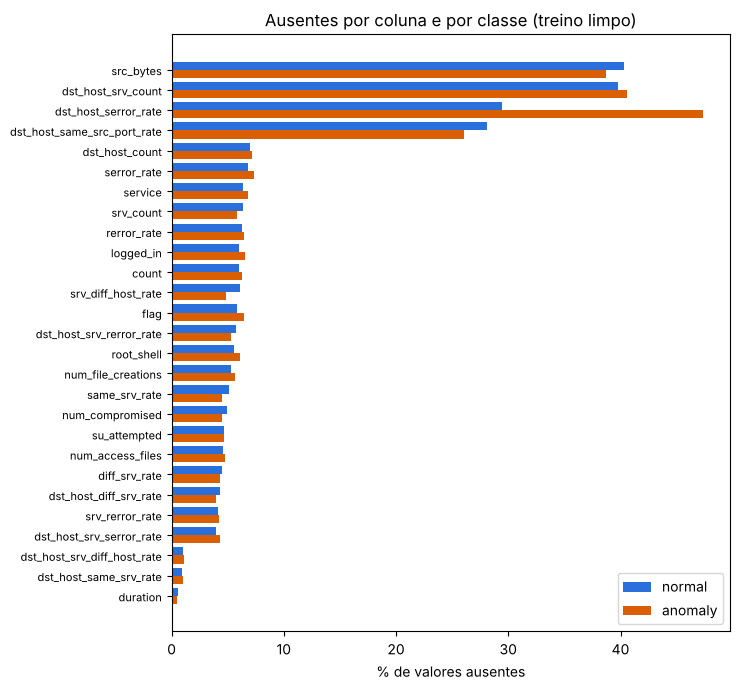

In [ ]:
# gráfico 1: % de ausentes por coluna, separado por classe
d = aus.iloc[::-1]
pos = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(pos + 0.2, d["normal (%)"], height=0.4, color=AZUL, label="normal")
ax.barh(pos - 0.2, d["anomaly (%)"], height=0.4, color=LARANJA, label="anomaly")
ax.set_yticks(pos)
ax.set_yticklabels(d.index, fontsize=8)
ax.set_xlabel("% de valores ausentes")
ax.set_title("Ausentes por coluna e por classe (treino limpo)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 1**

- 27 colunas têm ausentes: 25 numéricas e 2 de texto (`service` e `flag`). As que mais faltam são `src_bytes` (40,2%), `dst_host_srv_count` (39,8%), `dst_host_serror_rate` (30,0%) e `dst_host_same_src_port_rate` (28,1%). As outras ficam entre 0,5% e 7%.
- 94,2% das linhas do treino têm pelo menos um ausente. Se eu apagasse essas linhas, sobrariam 3.178 de 55.074, e no teste não dá para apagar nenhuma. Então a saída é imputar.
- As proporções são parecidas no treino e no teste. A exceção são `duration`, `dst_host_same_srv_rate` e `dst_host_srv_diff_host_rate`, que só têm ausentes no treino: esses ausentes vieram dos valores impossíveis que a Pessoa 1 transformou em `NaN`, e o teste não tinha nenhum.
- Em quase todas as colunas, a falta é igual nas duas classes (diferença de no máximo 2,1 pontos percentuais). A exceção é `dst_host_serror_rate`: falta em 29,4% das normais e em 47,4% das anomalias. Mesmo assim, o indicador "está ausente" dessa coluna, sozinho, separa pouco as classes (AUC de 0,59, em que 0,5 é não separar nada).

## 2. Imputação

Comparo seis formas de preencher os ausentes, todas com o `service` em one-hot:

- **mediana** (referência): não é puxada pelos valores extremos, e bytes e contagens são muito assimétricos;
- **média**: a alternativa simples, mas sofre com os extremos;
- **mediana + indicador de `dst_host_serror_rate`**: além de preencher, cria uma coluna 0/1 dizendo se o valor estava ausente, só na coluna em que a Etapa 1 viu a ausência ligada à classe;
- **mediana + indicadores em todas**: a mesma ideia, uma coluna 0/1 para cada atributo com ausente (`add_indicator=True`);
- **iterativa** (`IterativeImputer`): prevê cada coluna ausente a partir das outras, em rodadas. É a alternativa multivariada;
- **mediana + categoria "ausente" nos textos**: em vez de usar a moda, o `service` ou a `flag` ausente vira uma categoria própria.

Nos textos, a referência é a moda (o valor mais comum).

Também pensei no `KNNImputer`. Num teste com um fold, ele levou cerca de 40 segundos só para preencher as 11 mil linhas da validação; o treino de cada fold é 4 vezes maior, e isso se repetiria em 10 folds e 2 modelos. Deixei de fora pelo custo, e a iterativa já cobre a ideia de usar as outras colunas para preencher.

In [ ]:
# codificação fixa (one-hot) para isolar o efeito da imputação
TEC_IMP = {
    "mediana (referência)":          dict(num="mediana", cat="moda", codificacao="onehot"),
    "média":                         dict(num="media", cat="moda", codificacao="onehot"),
    "mediana + indicador serror":    dict(num="mediana+indicador_serror", cat="moda", codificacao="onehot"),
    "mediana + indicadores (todas)": dict(num="mediana+indicadores", cat="moda", codificacao="onehot"),
    "iterativa (multivariada)":      dict(num="iterativa", cat="moda", codificacao="onehot"),
    "mediana + cat. 'ausente'":      dict(num="mediana", cat="constante", codificacao="onehot"),
}
res_imp, folds_imp = comparar(TEC_IMP, referencia="mediana (referência)")
display(res_imp.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,mediana (referência),0.9302,0.0053,6.6147,0.0000,0/10
1,Regressão logística,média,0.9304,0.0059,5.6335,0.0001,4/10
2,Regressão logística,mediana + indicador serror,0.9296,0.0060,6.7146,-0.0007,3/10
3,Regressão logística,mediana + indicadores (todas),0.9300,0.0042,7.6346,-0.0002,5/10
4,Regressão logística,iterativa (multivariada),0.9322,0.0067,37.3074,0.0019,7/10
5,Regressão logística,mediana + cat. 'ausente',0.9332,0.0056,7.2262,0.0030,8/10
6,Random forest,mediana (referência),0.9728,0.0043,24.3344,0.0000,0/10
7,Random forest,média,0.9703,0.0050,22.5771,-0.0025,1/10
8,Random forest,mediana + indicador serror,0.9711,0.0048,23.7084,-0.0017,2/10
9,Random forest,mediana + indicadores (todas),0.9691,0.0059,24.7539,-0.0037,0/10


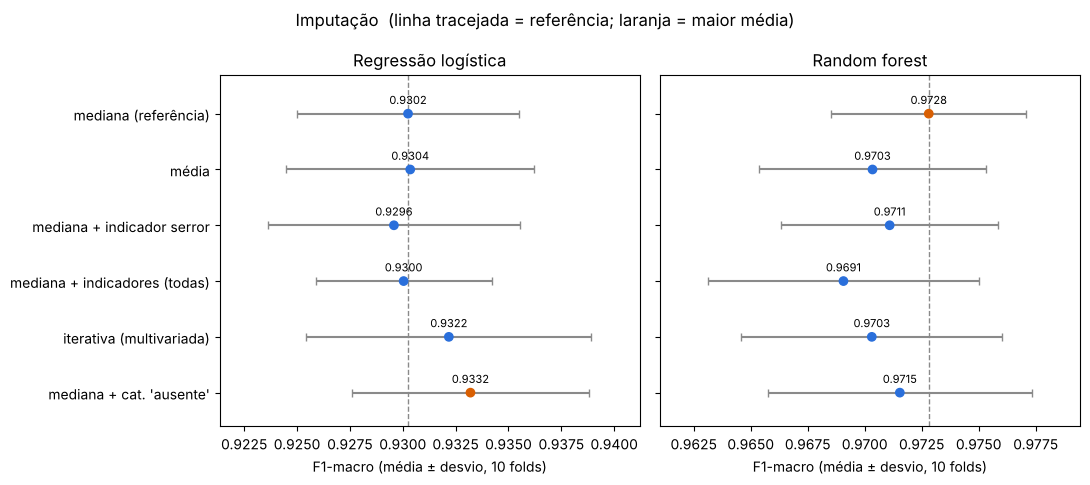

In [ ]:
def grafico_comparacao(res, titulo):
    """Um painel por modelo: média do F1-macro nos 10 folds, com o desvio padrão."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * res["técnica"].nunique() + 1.6), sharey=True)
    ordem = list(dict.fromkeys(res["técnica"]))[::-1]
    for ax, (modelo, r) in zip(axes, res.groupby("modelo", sort=False)):
        r = r.set_index("técnica").loc[ordem]
        ref = r.iloc[-1]["F1-macro"]   # a referência é a primeira técnica da lista
        melhor = r["F1-macro"].idxmax()
        cores = [LARANJA if t == melhor else AZUL for t in r.index]
        ax.errorbar(r["F1-macro"], np.arange(len(r)), xerr=r["desvio"], fmt="none", ecolor=CINZA, capsize=3)
        ax.scatter(r["F1-macro"], np.arange(len(r)), color=cores, zorder=3)
        ax.axvline(ref, color=CINZA, ls="--", lw=1)
        for i, v in enumerate(r["F1-macro"]):
            ax.annotate(f"{v:.4f}", (v, i), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
        ax.set_ylim(-0.6, len(r) - 0.3)   # espaço para o número da primeira linha
        ax.set_yticks(np.arange(len(r)))
        ax.set_yticklabels(r.index)
        ax.set_title(modelo)
        ax.set_xlabel("F1-macro (média ± desvio, 10 folds)")
        lo = (r["F1-macro"] - r["desvio"]).min(); hi = (r["F1-macro"] + r["desvio"]).max()
        ax.set_xlim(lo - (hi - lo) * 0.15, hi + (hi - lo) * 0.15)
    fig.suptitle(titulo + "  (linha tracejada = referência; laranja = maior média)")
    plt.tight_layout(); plt.show()

grafico_comparacao(res_imp, "Imputação")

In [ ]:
IMP_NOME = escolher(res_imp, referencia="mediana (referência)")

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
mediana (referência),0.0000,0.0000,—,—,—
média,-0.0025,0.0001,False,False,False
mediana + indicador serror,-0.0017,-0.0007,False,False,False
mediana + indicadores (todas),-0.0037,-0.0002,False,False,False
iterativa (multivariada),-0.0025,0.0019,False,False,False
mediana + cat. 'ausente',-0.0013,0.0030,False,True,False


Escolhida: mediana (referência)


**Conclusão do passo 2**

- Na random forest, nenhuma alternativa bateu a mediana: todas tiveram média menor e perderam na maioria dos folds. A pior foi colocar indicadores em todas as colunas (−0,0037, ganhou em 0 de 10 folds).
- Na regressão logística, a categoria "ausente" nos textos foi a melhor (+0,0030, ganhou em 8 de 10 folds), e a iterativa também ajudou (+0,0019, ganhou em 7 de 10 folds). Mas as duas pioram a random forest, e a iterativa ainda demora cerca de 3 vezes mais que a mediana.
- Os indicadores de ausência não ajudaram em nenhum dos dois modelos, nem o de `dst_host_serror_rate` que a Etapa 1 sugeriu testar (−0,0007, ganhou em 3 de 10 folds na regressão logística, −0,0017, ganhou em 2 de 10 folds na random forest). A diferença entre as classes existe, mas é fraca, como o passo 1 mostrou. E os indicadores em todas as colunas criam três colunas que no teste são sempre 0 (`duration` e as duas taxas do passo 1), porque lá nunca falta valor nelas.
- **Escolha: mediana nos números e moda nos textos.** Nenhuma alternativa passou na regra, porque todas pioram a random forest. Ela também é simples e rápida.
- Se o grupo acabar usando um modelo linear, vale trocar a moda pela categoria "ausente" nos textos (`cat="constante"` no `montar_preprocessador`).

## 3. Codificação dos categóricos

`protocol_type` (3 valores) e `flag` (11 valores) têm poucas categorias, então ficam sempre em one-hot. O problema é o `service`. Antes de comparar, vejo quantas categorias ele tem, quantas são raras, se o teste traz alguma que o treino não tem e quantas colunas cada codificação gera.

In [ ]:
cont = X["service"].value_counts()
raras = cont[cont < 50]
so_teste = sorted(set(X_teste["service"].dropna()) - set(cont.index))

print(f"service: {len(cont)} categorias no treino (protocol_type tem {X['protocol_type'].nunique()} e flag tem {X['flag'].nunique()})")
print(f"As 5 maiores cobrem {cont.head(5).sum() / cont.sum() * 100:.1f}% das linhas: {cont.head(5).index.tolist()}")
print(f"Categorias com menos de 50 linhas: {len(raras)} (somam {raras.sum()} linhas, {raras.sum() / cont.sum() * 100:.2f}%)")
print(f"Categorias com 1 linha só: {(cont == 1).sum()} -> {cont[cont == 1].index.tolist()}")
print(f"Serviços do teste que não existem no treino limpo: {so_teste} "
      f"({X_teste['service'].isin(so_teste).sum()} linhas do teste)")

# a codificação por frequência junta categorias que têm a mesma contagem
repetidas = cont.groupby(cont).size()
repetidas = repetidas[repetidas > 1]
print(f"Frequência: {repetidas.sum()} categorias dividem o mesmo valor com outra ({len(repetidas)} valores repetidos)")

# taxa de anomalia por serviço: mostra que categorias diferentes com a mesma frequência podem ter classe bem diferente
taxa = (y.groupby(X["service"]).mean() * 100).rename("% anomaly")
por_serv = pd.DataFrame({"linhas": cont, "% anomaly": taxa})
amplitude = por_serv[por_serv["linhas"].isin(repetidas.index)].groupby("linhas")["% anomaly"].agg(lambda t: t.max() - t.min())
n_ex = amplitude.idxmax()   # a contagem repetida em que os serviços são mais diferentes entre si
print(f"\nExemplo de colisão: serviços com exatamente {n_ex} linhas no treino (viram o mesmo número na frequência)")
display(por_serv[por_serv["linhas"] == n_ex].round(1))

# quantas colunas cada codificação gera no treino inteiro
n_cols = {}
for cod in ["onehot", "onehot_raras", "frequencia", "alvo", "ordinal"]:
    pre = montar_preprocessador(num="mediana", cat="moda", codificacao=cod)
    n_cols[cod] = pre.fit(X, y).transform(X.head(5)).shape[1]
display(pd.Series(n_cols, name="colunas na saída").to_frame())

service: 65 categorias no treino (protocol_type tem 3 e flag tem 11)
As 5 maiores cobrem 88.6% das linhas: ['http', 'domain_u', 'smtp', 'ftp_data', 'private']
Categorias com menos de 50 linhas: 48 (somam 605 linhas, 1.17%)
Categorias com 1 linha só: 2 -> ['pop_2', 'http_2784']
Serviços do teste que não existem no treino limpo: ['pm_dump', 'printer'] (2 linhas do teste)
Frequência: 40 categorias dividem o mesmo valor com outra (14 valores repetidos)

Exemplo de colisão: serviços com exatamente 3 linhas no treino (viram o mesmo número na frequência)


,linhas,% anomaly
service,,
remote_job,3,100.0
shell,3,33.3
tftp_u,3,0.0


,colunas na saída
onehot,116
onehot_raras,69
frequencia,52
alvo,52
ordinal,52


**O que o diagnóstico mostra sobre o `service`**

- São 65 categorias, mas as 5 maiores cobrem 88,6% das linhas. 48 categorias têm menos de 50 linhas (juntas, só 1,17% do treino) e 2 aparecem uma vez só. Com one-hot, cada uma vira uma coluna quase sempre zerada, e a base sai de 40 para 116 colunas.
- O teste tem 2 serviços que não existem no treino limpo: `pm_dump` e `printer` (1 linha cada). Eles existiam no treino original, mas todas as linhas deles estavam em grupos contraditórios (atributos iguais, classes diferentes) e saíram na limpeza. A codificação precisa aceitar categoria desconhecida sem dar erro.
- Na codificação por frequência, serviços com a mesma contagem viram o mesmo número: 40 serviços dividem o valor com algum outro. No exemplo acima, três serviços com 3 linhas cada vão de 0% a 100% de anomalias e mesmo assim ficariam iguais para o modelo.

Comparo cinco codificações para o `service`, todas com a imputação escolhida no passo 2:

- **one-hot** (referência): uma coluna por serviço (116 colunas no total);
- **one-hot com raras juntas** (`min_frequency=50`): serviços com menos de 50 linhas no treino do fold viram uma coluna só, e um serviço desconhecido no teste cai nessa mesma coluna (69 colunas);
- **frequência**: uma coluna com a proporção de linhas de cada serviço no treino; serviço desconhecido vira 0 (52 colunas);
- **alvo** (*target encoding*, `TargetEncoder`): uma coluna com a taxa de anomalia de cada serviço. Dentro do `fit` ele usa validação cruzada interna, para que nenhuma linha seja codificada com o próprio rótulo (52 colunas);
- **ordinal**: um número por serviço, em ordem alfabética. Entra como contraexemplo, porque inventa uma ordem que não existe (52 colunas).

In [ ]:
# imputação fixa (a escolhida no passo 2) para isolar o efeito da codificação
IMP_ESCOLHIDA = {k: v for k, v in TEC_IMP[IMP_NOME].items() if k != "codificacao"}
TEC_COD = {
    "one-hot (referência)":       dict(**IMP_ESCOLHIDA, codificacao="onehot"),
    "one-hot com raras juntas":   dict(**IMP_ESCOLHIDA, codificacao="onehot_raras"),
    "frequência":                 dict(**IMP_ESCOLHIDA, codificacao="frequencia"),
    "alvo (target encoding)":     dict(**IMP_ESCOLHIDA, codificacao="alvo"),
    "ordinal":                    dict(**IMP_ESCOLHIDA, codificacao="ordinal"),
}
res_cod, folds_cod = comparar(TEC_COD, referencia="one-hot (referência)")
display(res_cod.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,one-hot (referência),0.9302,0.0053,6.5620,0.0000,0/10
1,Regressão logística,one-hot com raras juntas,0.9308,0.0057,5.2260,0.0006,5/10
2,Regressão logística,frequência,0.9183,0.0049,4.3836,-0.0119,0/10
3,Regressão logística,alvo (target encoding),0.9321,0.0059,4.2553,0.0019,7/10
4,Regressão logística,ordinal,0.9108,0.0037,4.3192,-0.0195,0/10
5,Random forest,one-hot (referência),0.9728,0.0043,22.4037,0.0000,0/10
6,Random forest,one-hot com raras juntas,0.9750,0.0041,23.2298,0.0022,10/10
7,Random forest,frequência,0.9745,0.0045,22.9492,0.0017,6/10
8,Random forest,alvo (target encoding),0.9748,0.0041,22.6937,0.0020,6/10
9,Random forest,ordinal,0.9735,0.0054,21.0913,0.0007,6/10


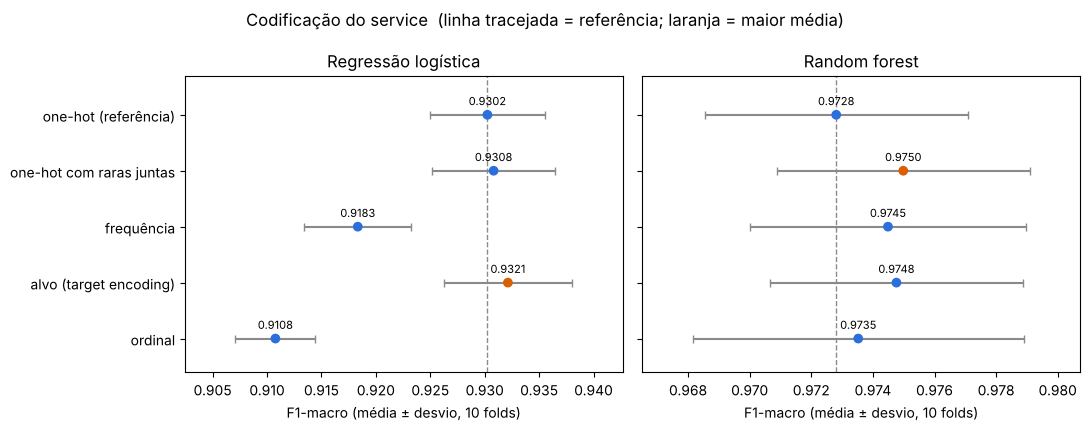

In [ ]:
grafico_comparacao(res_cod, "Codificação do service")

In [ ]:
COD_NOME = escolher(res_cod, referencia="one-hot (referência)")
ESCOLHA = TEC_COD[COD_NOME]

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
one-hot (referência),0.0000,0.0000,—,—,—
one-hot com raras juntas,0.0022,0.0006,True,True,True
frequência,0.0017,-0.0119,False,False,False
alvo (target encoding),0.0020,0.0019,True,False,False
ordinal,0.0007,-0.0195,False,False,False


Escolhida: one-hot com raras juntas


**Conclusão do passo 3**

- **One-hot com raras juntas** ganhou da referência na random forest em todos os 10 folds (+0,0022, ganhou em 10 de 10 folds) e empatou na regressão logística (+0,0006, ganhou em 5 de 10 folds). Juntar os serviços raros tira 47 colunas quase sempre zeradas, que apareciam em tão poucas linhas que davam pouco para o modelo aprender.
- A codificação pelo **alvo** chegou perto: melhorou os dois modelos (+0,0019, ganhou em 7 de 10 folds na regressão logística e +0,0020, ganhou em 6 de 10 folds na random forest) e teve a maior média na regressão logística. Mas não ganhou em 8 dos 10 folds em nenhum dos dois, então pela regra não dá para separar essa melhora de sorte na divisão dos folds. Ela também é a única que usa o rótulo para codificar, o que pede mais cuidado.
- **Frequência** ajudou um pouco a random forest (+0,0017, ganhou em 6 de 10 folds), mas derrubou a regressão logística (−0,0119, ganhou em 0 de 10 folds), que perdeu nos 10 folds. É o efeito das colisões: serviços diferentes viram o mesmo número, e um modelo linear ainda lê esse número como "mais é maior".
- **Ordinal** foi a pior na regressão logística (−0,0195, ganhou em 0 de 10 folds), como esperado: a ordem alfabética não quer dizer nada. Na random forest quase não mudou (+0,0007, ganhou em 6 de 10 folds), porque as árvores conseguem separar os números em vários cortes.
- **Escolha: one-hot com raras juntas.** Foi a única que passou na regra. Ela não depende do rótulo (sem risco de vazamento), trata os serviços novos do teste e entrega 69 colunas em vez de 116, o que também deixa mais leve o PCA da Pessoa 3 e o SMOTE da Pessoa 4.

## 4. Conferindo a escolha no teste

Ajusto o pré-processamento escolhido no treino inteiro e aplico no teste, que é o que a Pessoa 4 vai fazer no final. Confiro que não sobra nenhum `NaN`, que o teste continua com todas as linhas, que treino e teste saem com as mesmas colunas e que os dois serviços novos do teste não quebram nada.

In [ ]:
# a configuração escolhida, do jeito que a Pessoa 4 vai usar
pre_final = montar_preprocessador(**ESCOLHA)
pre_final.fit(X, y)
Xt_treino = pre_final.transform(X)
Xt_teste = pre_final.transform(X_teste)
nomes = pre_final.get_feature_names_out()

conferencias = {
    "nenhum NaN depois do pré-processamento (treino)": not np.isnan(Xt_treino).any(),
    "nenhum NaN depois do pré-processamento (teste)": not np.isnan(Xt_teste).any(),
    "teste continua com 24.333 linhas": Xt_teste.shape[0] == 24333,
    "treino e teste com as mesmas colunas": Xt_treino.shape[1] == Xt_teste.shape[1],
    "serviços novos do teste caem na coluna dos raros": bool(
        (Xt_teste[X_teste["service"].isin(so_teste).to_numpy(), list(nomes).index("service_infrequent_sklearn")] == 1).all()),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())
print(f"\nEscolha: {ESCOLHA}")
print(f"Colunas na saída: {Xt_treino.shape[1]} (eram {X.shape[1]} atributos)")
print("Algumas colunas:", list(nomes[:3]), "...", list(nomes[-4:]))

OK   nenhum NaN depois do pré-processamento (treino)
OK   nenhum NaN depois do pré-processamento (teste)
OK   teste continua com 24.333 linhas
OK   treino e teste com as mesmas colunas
OK   serviços novos do teste caem na coluna dos raros

Escolha: {'num': 'mediana', 'cat': 'moda', 'codificacao': 'onehot_raras'}
Colunas na saída: 69 (eram 40 atributos)
Algumas colunas: ['duration', 'src_bytes', 'dst_bytes'] ... ['service_telnet', 'service_time', 'service_urp_i', 'service_infrequent_sklearn']


**Conclusão do passo 4**

- O pré-processamento roda no teste sem erro e sem deixar `NaN`. As 24.333 linhas continuam lá, com as mesmas 69 colunas do treino.
- `pm_dump` e `printer`, que não existem no treino, caem na coluna dos serviços raros (`service_infrequent_sklearn`), em vez de virarem uma linha toda zerada ou darem erro.

## 5. Resumo

Todas as técnicas testadas, com a média do F1-macro nos 10 folds. Os números saem das variáveis do notebook, não foram digitados.

In [ ]:
fmt4 = lambda v: f"{v:.4f}"
def linha(res, tec):
    r = res[res["técnica"] == tec].set_index("modelo")
    return [fmt4(r.loc["Regressão logística", "F1-macro"]), fmt4(r.loc["Random forest", "F1-macro"])]

tab = pd.DataFrame(
    [["Imputação", t] + linha(res_imp, t) for t in TEC_IMP] +
    [["Codificação do service", t] + linha(res_cod, t) for t in TEC_COD],
    columns=["etapa", "técnica", "F1-macro (reg. logística)", "F1-macro (random forest)"])
tab["escolhida"] = ["sim" if t in (IMP_NOME, COD_NOME) else "" for t in tab["técnica"]]
display(tab.style.hide(axis="index"))

etapa,técnica,F1-macro (reg. logística),F1-macro (random forest),escolhida
Imputação,mediana (referência),0.9302,0.9728,sim
Imputação,média,0.9304,0.9703,
Imputação,mediana + indicador serror,0.9296,0.9711,
Imputação,mediana + indicadores (todas),0.9300,0.9691,
Imputação,iterativa (multivariada),0.9322,0.9703,
Imputação,mediana + cat. 'ausente',0.9332,0.9715,
Codificação do service,one-hot (referência),0.9302,0.9728,
Codificação do service,one-hot com raras juntas,0.9308,0.9750,sim
Codificação do service,frequência,0.9183,0.9745,
Codificação do service,alvo (target encoding),0.9321,0.9748,


**Para quem for usar (Pessoa 4):**

```python
from ausentes_codificacao import montar_preprocessador

pre = montar_preprocessador(num="mediana", cat="moda", codificacao="onehot_raras")
pipe = Pipeline([("pre", pre), ("modelo", ...)])   # o pré-processamento vem antes de tudo
```

- O `montar_preprocessador()` já inclui um `StandardScaler` nos números. Se a Pessoa 3 escolher outro tratamento (`log1p`, `RobustScaler`), é só trocar essa parte no arquivo.
- Ele tem que ser o **primeiro passo** do pipeline, antes do SMOTE: o SMOTE trabalha com distâncias, então precisa receber tudo já sem `NaN` e em números.
- `X` não pode ter `class` nem `id`. Com `score_ids_legado`, ela entra automaticamente como mais uma coluna numérica.
- Quando o `avaliar()` oficial da Pessoa 1 sair, vale rodar esta seção de novo com ele. Se as escolhas mudarem, a função `escolher()` mostra isso na hora; só o texto das conclusões teria que ser atualizado.